# SpotMAX as a Python package

Here we show a simple example where we detect and quantify spots in synthetic data. 

We will use a single call to the `predict` method of the SpotMAX model.

For an example about how to use the different modules separately, see the notebook `notebooks/spots_synthetic_simple_steps.ipynb`

*NOTE: While default parameters work with this simple image, we **highly recommend** reading the documentation in order to learn how to change the parameters.* 

In [1]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

import spotmax as sm

## Generate synthetic data

In [2]:
spots_radii = np.array([4, 6, 6])

spots_img, spots_gt_mask, spots_coords, df_spots_coords  = (
    sm.data.synthetic_spots(
        num_spots=20,
        shape=(25, 256, 256), 
        spots_radii=spots_radii, 
        noise_scale=0.05,
        noise_shape=0.03, 
        return_df=True,
        rng_seed=11
    )
)
spots_img.shape

(25, 256, 256)

## Visualize max z-projection

Text(0.5, 1.0, 'Spots mask MAX z-projection')

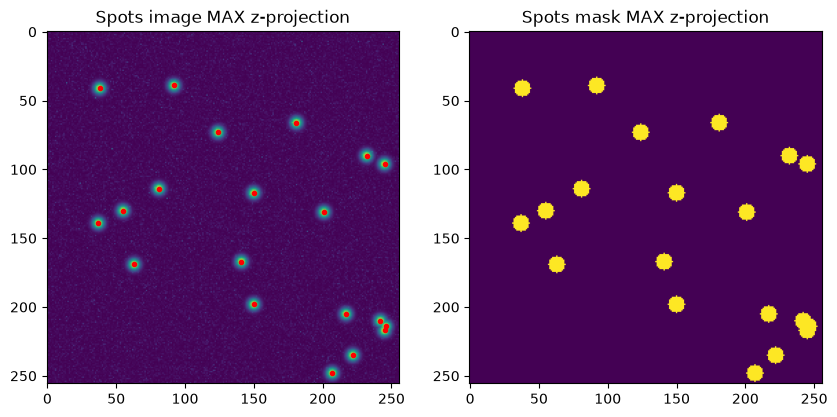

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(10, 6))
ax[0].imshow(spots_img.max(axis=0))
ax[0].plot(spots_coords[:,2], spots_coords[:,1], 'r.')
ax[0].set_title('Spots image MAX z-projection')

ax[1].imshow(spots_gt_mask.max(axis=0))
# ax[1].plot(spots_coords[:,2], spots_coords[:,1], 'r.')
ax[1].set_title('Spots mask MAX z-projection')

## Run the prediction

### Initialise model

**Objective**: detect, validate, and quantify spots \
**Method**: single call to the `predict` method of SpotMAX Model.

NOTE: for the argument `segmentation_kwargs` see `spotmax.pipe.spots_semantic_segmentation` function.

In [4]:
from spotmax import Model

spots_zyx_radii_pxl = spots_radii

# Keyword arguments for `spotmax.pipe.spots_semantic_segmentation`
segmentation_kwargs = {
    'thresholding_method': 'threshold_li',
    'do_sharpen': True
}

# Keyword arguments for `spotmax.pipe.spot_detection`
detection_kwargs = {}

# Keyword arguments for `spotmax.pipe.spots_calc_features_and_filter`
gop_filtering_thresholds = sm.config.get_features_thresholds_filter(
    'spot_vs_backgr_effect_size_glass, 0'
)
features_kwargs = {
    'gop_filtering_thresholds': gop_filtering_thresholds,
    'optimise_for_high_spot_density': True,
    'show_progress': False,
    'verbose': False,
}

# Keyword arguments for `spotmax.pipe.spotfit`
spotfit_kwargs = {
    'verbose': True
}

model = Model(
    spots_zyx_radii_pxl,
    zyx_voxel_size=None,
    segmentation_kwargs=segmentation_kwargs,
    detection_kwargs=detection_kwargs,
    features_kwargs=features_kwargs,
    spotfit_kwargs=spotfit_kwargs,
    spotfit_check_merge=True,
)

gop_filtering_thresholds

{'spot_vs_backgr_effect_size_glass': (0.0, None)}

In [6]:
df_spots_spotfit, extras = model.predict(
    spots_img,
    return_features=True,
    return_masks=True,
    return_preprocessed=True,
)

columns = [
    'z', 'y', 'x', 'spot_center_raw_intensity', 
    'spot_vs_backgr_effect_size_glass'
]

df_spots_spotfit[columns].head(10)


*****************************************************************************
Frame n. 1: number of spots after filtering valid spots according to spotFIT:

All spots are valid
-----------------------------------------------------------------------------


z    y    x  spot_center_raw_intensity  spot_vs_backgr_effect_size_glass
Cell_ID spot_id                                                                           
1       1        14  167  141                   0.993988                         15.115718
        2        14  114   81                   0.992468                         15.114997
        3        16  235  222                   0.992468                         14.883358
        4        13   66  181                   0.992470                         14.775211
        5        12  130   55                   0.992468                         14.960445
        6        13  117  150                   0.994681                         14.774138
        7        14  139   37                   0.992468                         15.077006
        8         5  169   63                   0.992468                         19.494211
        9        17   41   38                   0.992487                         15.140796
        10        6  131  201                   0.992468                         18.615037

Text(0.5, 1.0, 'SpotFIT labels MAX z-projection')

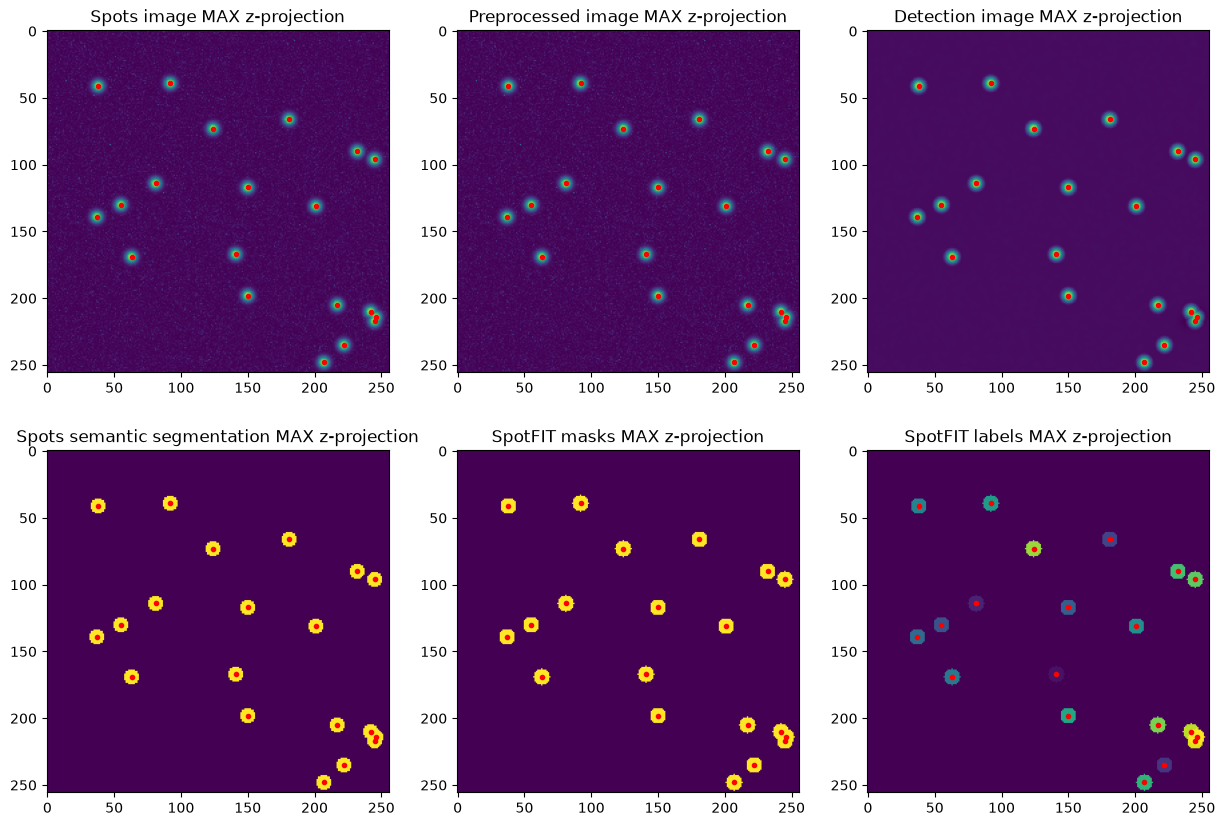

In [9]:
spots_pred_mask = extras['masks']['segmentation']
spotfit_mask = extras['masks']['fitted']['mask']
spotfit_labels = extras['masks']['fitted']['labels']
preprocessed_image = extras['preprocessed_images']['preprocessed']
detection_image = extras['preprocessed_images']['detection']

fig, ax = plt.subplots(2, 3, figsize=(15, 10))
ax[0, 0].imshow(spots_img.max(axis=0))
ax[0, 0].plot(df_spots_spotfit['x'], df_spots_spotfit['y'], 'r.')
ax[0, 0].set_title('Spots image MAX z-projection')

ax[0, 1].imshow(preprocessed_image.max(axis=0))
ax[0, 1].plot(df_spots_spotfit['x'], df_spots_spotfit['y'], 'r.')
ax[0, 1].set_title('Preprocessed image MAX z-projection')

ax[0, 2].imshow(detection_image.max(axis=0))
ax[0, 2].plot(df_spots_spotfit['x'], df_spots_spotfit['y'], 'r.')
ax[0, 2].set_title('Detection image MAX z-projection')

ax[1, 0].imshow(spots_pred_mask.max(axis=0))
ax[1, 0].plot(df_spots_spotfit['x'], df_spots_spotfit['y'], 'r.')
ax[1, 0].set_title('Spots semantic segmentation MAX z-projection')

ax[1, 1].imshow(spotfit_mask.max(axis=0))
ax[1, 1].plot(df_spots_spotfit['x'], df_spots_spotfit['y'], 'r.')
ax[1, 1].set_title('SpotFIT masks MAX z-projection')

ax[1, 2].imshow(spotfit_labels.max(axis=0))
ax[1, 2].plot(df_spots_spotfit['x'], df_spots_spotfit['y'], 'r.')
ax[1, 2].set_title('SpotFIT labels MAX z-projection')

